# Step 16: the BreastDCEDL paper's model, reproduced as published and with our fixes (GPU T4, ~2-3 h)
The BreastDCEDL paper (Fridman et al., arXiv 2506.12190) reports **AUC 0.94 / accuracy 0.93**. That number is one
subgroup: I-SPY2 HR+/HER2- test patients with clinical features, **N = 40 with 5 pCR** (their Figure 4C: 35 true
negatives, 2 true positives, 3 missed). Always predicting "no pCR" already scores 87.5% accuracy there, and an AUC from
5 positives has a 95% CI roughly 0.8-1.0. Their whole test set (177 patients, all cohorts) scored **AUC 0.72**,
Duke 0.54. Their I-SPY2 model also used the MammaPrint score and the I-SPY2 drug arms, which are **not in the
released metadata** (checked: the public CSV has the same 29 columns as ours).

This notebook does what they did, on our data, under our evaluation rules, so the numbers can be compared fairly:

| | paper (as published) | fixed (this project's lessons) |
|---|---|---|
| input | RGB fusion: pre -> R, early -> G, late -> B | same |
| slices | 4 around the tumour's middle slice | every tumour slice (up to 16); 4 random, area-weighted, per epoch |
| crop | 224 pixels at the native pixel size (70-315 mm) | the same 100 mm for every patient, resized to 224 |
| intensity | min-max per image | one window per patient (keeps enhancement + slice differences) |
| network | `facebook/vit-mae-base` fine-tuned, [CLS] -> pCR + HR + HER2 heads | same backbone, pCR head only (step 12: extra heads hurt) |
| patient score | mean / min of slice probabilities | + max, tumour-area-weighted mean |
| stage 2 | Random Forest: DL scores + tumour volume + box volume + age, HR, HER2, race | RF **and** logistic regression; same features |

Evaluation (unchanged project rules): the ViT is trained in **5-fold CV on the 1,098 training patients**, so every
training patient gets a score from a model that never saw it (no leakage into stage 2); val (177) = mean of the 5
fold models. Stage 2: 5 x 5-fold CV. **The test split is never loaded.** Results are also printed in the
**paper's Table 2 layout** (accuracy, AUC with 95% CI, sensitivity, specificity, precision, NPV per subtype and
cohort) next to the accuracy of always predicting "no pCR", plus an **I-SPY2-only** model like theirs.

Kaggle setup: Accelerator **GPU T4 x2** (one GPU is used), Internet **ON** (downloads `facebook/vit-mae-base`).
**+ Add Input**:
- the caches, best first: **`mnj-cache2-ispy1/-ispy2/-duke`** (raw), else **`mnj-cache-v2`**, else the
  `mnj-cache-ispy1/-ispy2/-duke` v1 caches (works; the brightest enhancement is clipped);
- the code: the **`mnj-code-vaib`** Dataset (the same version as for step 15);
- optional: **your step-15 notebook output** (its `stack_inputs.csv` adds the self-supervised 3D score to stage 2).

Run with `DEBUG = True` first (25 patients per split and cohort, 2 epochs: ~10 min), then `DEBUG = False` with
**Save Version -> Save & Run All (Commit)**. Every step prints a timestamped `[...]` line.
Results: Output tab, `results/<PERSON>/step16/RESULTS_step16.md`.

In [1]:
# ==== PARAMETERS (edit these) ====
REPO = "AkulaReddy/MRI_chemo_response"
GIT_TAG = "vaib"           # branch (or tag) to clone
PERSON = ""               # optional: "A", "B" or "C" -> results/<PERSON>/ (empty -> results/vaib/)
STEP = "step16"
CACHE_ORDER = ["raw", "uint8_v2", "uint8_v1"]   # per cohort, the first kind attached that loads
VARIANTS = ["paper", "fixed"]                  # "paper" = as published, "fixed" = with our fixes
BACKBONE = "facebook/vit-mae-base"             # the paper's checkpoint
IMG_SIZE = 224
PAPER_SLICES = 4             # the paper's code: range(mid - 2, mid + 2)
FIX_MAX_SLICES = 16          # fixed: every tumour slice, at most this many (evenly spaced)
FIX_CROP_MM = 100.0          # fixed: field of view of every crop
TRAIN_SLICES = 4             # fixed: tumour slices drawn per patient per epoch (area-weighted)
MULTITASK = {"paper": True, "fixed": False}   # HR + HER2 heads next to pCR (paper, Figure 2)
EPOCHS = 12
PATIENCE = 3                 # early stopping on an inner 15% of each training fold (patient-level AUC)
BATCH = 32
LR_BACKBONE, LR_HEAD, WD = 3e-5, 1e-3, 0.05
VIT_REPEATS = 1              # outer CV repeats for the ViT (x 5 folds)
STAGE2_REPEATS = 5           # repeated 5-fold CV for stage 2
STAGE2_KINDS = ["rf", "lr"]  # rf = the paper's Random Forest, lr = logistic regression
THRESHOLD = 0.5              # for accuracy / sensitivity / specificity in the paper-style tables
USE_STEP15 = True            # add the step-15 self-supervised 3D score when its output is attached
JOBS = 4
SEED = 0
EXTRA_PIP = []
TIME_BUDGET_H = 11.0
DEBUG = False                # True: 25 patients per split and cohort, 2 epochs, 2 CV repeats
PUSH_RESULTS = False
NOTEBOOK_NAME = "step16"

In [2]:
# ==== SETUP (do not edit): get the repo code, install requirements ====
import base64, glob, json, os, shutil, subprocess, sys, zipfile
if PERSON not in ("A", "B", "C"):           # only names the results folder
    PERSON = "vaib"
    print('PERSON not set: results go to results/vaib/ (set PERSON = "A", "B" or "C" to change)')
NEEDS = "src/vitonly/rcv.py"               # the steps 11-13 code (in the mnj-code-vaib zip made on 2026-11-04 or later)
_tok = None
try:
    from kaggle_secrets import UserSecretsClient
    _tok = UserSecretsClient().get_secret("GITHUB_TOKEN")
except Exception as e:
    print("no GITHUB_TOKEN secret attached to this notebook (fine if the mnj-code-vaib Dataset is attached):",
          type(e).__name__)

def git(*args, cwd="/tmp/repo"):
    """git with the token as a one-off header (never stored in .git/config or the output)."""
    if not _tok:
        raise RuntimeError("no GITHUB_TOKEN secret: git push/pull is not available")
    hdr = "Authorization: Basic " + base64.b64encode(f"x-access-token:{_tok}".encode()).decode()
    r = subprocess.run(["git", "-c", f"http.extraHeader={hdr}", *args], cwd=cwd, capture_output=True, text=True)
    out = (r.stdout + r.stderr).replace(_tok, "***")
    if r.returncode:
        raise RuntimeError(f"git {args[0]} failed:\n{out}")
    return out

def _find_code():
    """An attached code Dataset that already has the steps 11-13 code (an unpacked folder or the uploaded zip)."""
    hits = [h for d in range(1, 8) for h in glob.glob("/kaggle/input/" + "*/" * d + NEEDS)]
    if not hits:
        for z in [z for d in range(1, 6) for z in glob.glob("/kaggle/input/" + "*/" * d + "mnj-code-vaib*.zip")]:
            zipfile.ZipFile(z).extractall("/tmp/code_zip")
        hits = glob.glob("/tmp/code_zip/**/" + NEEDS, recursive=True)
    return os.path.dirname(os.path.dirname(os.path.dirname(hits[0]))) if hits else None

shutil.rmtree("/tmp/repo", ignore_errors=True)
code_root = _find_code()
if code_root:                               # 1) the attached code Dataset with the new code wins
    shutil.copytree(code_root, "/tmp/repo")
    print("code: attached Dataset", code_root)
elif _tok:                                  # 2) or clone the branch from GitHub
    git("clone", "--quiet", "--depth", "1", "--branch", GIT_TAG, f"https://github.com/{REPO}.git", "/tmp/repo", cwd="/tmp")
    print("code: GitHub", REPO, GIT_TAG, git("log", "-1", "--format=%h %s"))
    if not os.path.exists(f"/tmp/repo/{NEEDS}"):
        raise SystemExit(f"branch {GIT_TAG} has no steps 11-13 code ({NEEDS}). Attach the NEW mnj-code-vaib zip "
                         "(+ Add Input -> Your Datasets -> mnj-code-vaib, latest version), or set GIT_TAG to a branch with it.")
else:
    print("attached inputs:")
    for root, dirs, files in os.walk("/kaggle/input"):
        if root.count("/") <= 5:
            print("  ", root, dirs[:6], files[:4])
        else:
            dirs[:] = []
    raise SystemExit(
        "\nThe notebook can't find the steps 11-13 code. Upload the new mnj-code-vaib.zip as a NEW VERSION of the\n"
        "mnj-code-vaib Dataset, then + Add Input -> Your Datasets -> mnj-code-vaib (latest version) and Run All again.")
os.chdir("/tmp/repo")
sys.path.insert(0, "/tmp/repo")         # so `from src...` works in this kernel
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-kaggle.txt"], check=True)
for pkg in EXTRA_PIP:                   # optional extras: a failed install is reported, never fatal
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], capture_output=True, text=True)
    print(f"pip install {pkg}:", "ok" if r.returncode == 0 else "FAILED (the step that needs it is skipped)\n" + r.stderr[-500:])
import torch; print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

PERSON not set: results go to results/vaib/ (set PERSON = "A", "B" or "C" to change)
no GITHUB_TOKEN secret attached to this notebook (fine if the mnj-code-vaib Dataset is attached): BackendError
code: attached Dataset /kaggle/input/datasets/a15chvaibhav/mnj-code-vaib/MRI_chemo_response
torch 2.11.0+cu130 | GPU: Tesla T4


In [3]:
# ==== HELPERS (do not edit): training runs, prediction files, comparisons ====
import glob, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import evaluation as ev, stats
from src.train import find_caches
from src.data.metadata import patient_table
COH = ["ispy1", "ispy2", "duke"]
OUT = f"/kaggle/working/results/{PERSON}/{STEP}"
os.makedirs(OUT, exist_ok=True)
T0 = time.time()
RUNS_JSON = {}
pd.set_option("display.width", 250, "display.max_columns", 40)

def budget_left():
    return TIME_BUDGET_H - (time.time() - T0) / 3600

def say(msg):
    """Timestamped progress line (elapsed and remaining budget), flushed so it shows in the Kaggle log at once."""
    el = (time.time() - T0) / 3600
    print(f"[{time.strftime('%H:%M:%S')} | {el:.2f} h elapsed, {budget_left():.2f} h left] {msg}", flush=True)

def run_cmd(cmd):
    """Run a training subprocess and stream its output line by line into this notebook (subprocess.run alone
    shows nothing until it ends, and the child's stdout is block-buffered without PYTHONUNBUFFERED)."""
    print("\n" + " ".join(cmd), flush=True)
    t = time.time()
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
                         env={**os.environ, "PYTHONUNBUFFERED": "1"})
    for line in p.stdout:
        print(line, end="", flush=True)
    if p.wait():
        raise subprocess.CalledProcessError(p.returncode, cmd)
    say(f"finished in {(time.time() - t) / 60:.1f} min")

def check_caches(version):
    caches = find_caches(["/kaggle/input", "/kaggle/working"])
    info = {c: json.load(open(f"{d}/cache_meta.json")).get("builder_version", 1) for c, d in caches.items()}
    print("caches:", {c: f"builder v{v}: {caches[c]}" for c, v in info.items()})
    if version is not None:
        bad = {c: v for c, v in info.items() if v != version}
        assert not bad and len(info) == 3, (f"need cache builder v{version} for all 3 cohorts (attach mnj-cache-v2); "
                                            f"found {info}")
    return caches

def _copy(d, label):
    os.makedirs(f"{OUT}/{label}", exist_ok=True)
    for f in ("val_preds.csv", "metrics.json", "log.csv", "config_resolved.yaml", "export_preds.csv",
              "train_preds.csv", "encoder.json"):
        if os.path.exists(f"{d}/{f}"):
            shutil.copy(f"{d}/{f}", f"{OUT}/{label}/{f}")

def train(config, seed, sets=(), label=None, cohorts=None):
    """One src.train run (B3 / F2 ...) -> (run_dir, metrics). Its small files are copied to OUT/<label>/."""
    cmd = [sys.executable, "-m", "src.train", "--config", config, "--seed", str(seed), "--out", "/kaggle/working/runs"]
    if CACHE_VERSION is not None: cmd += ["--cache-version", str(CACHE_VERSION)]
    if cohorts: cmd += ["--cohorts", *cohorts]
    if DEBUG: cmd.append("--debug")
    if sets: cmd += ["--set", *sets]
    run_cmd(cmd)
    d = max(glob.glob("/kaggle/working/runs/*/"), key=os.path.getmtime).rstrip("/")
    if label: _copy(d, label)
    return d, json.load(open(f"{d}/metrics.json"))

def finetune(config, seed, sets=(), label=None, cohorts=None):
    """One src.vitonly.finetune run (our pipeline: ViT-only vo_base / fusion vo_fusion) -> run_dir."""
    cmd = [sys.executable, "-m", "src.vitonly.finetune", "--config", config, "--seed", str(seed),
           "--cache-root", "/kaggle/input", "/kaggle/working", "--out", "/kaggle/working/runs"]
    if cohorts: cmd += ["--cohorts", *cohorts]
    if DEBUG: cmd.append("--debug")
    if sets: cmd += ["--set", *sets]
    run_cmd(cmd)
    d = max(glob.glob("/kaggle/working/runs/*/"), key=os.path.getmtime).rstrip("/")
    if label: _copy(d, label)
    return d

def note_runs(key, dirs):
    """label -> run folder names, in OUT/runs.json: step 8 uses it to find the checkpoints."""
    RUNS_JSON[key] = [os.path.basename(d) for d in dirs]
    json.dump(RUNS_JSON, open(f"{OUT}/runs.json", "w"), indent=1)

def preds_of(dirs):
    fr = [ev.load_preds(f"{d}/val_preds.csv") for d in dirs]
    return fr[0] if len(fr) == 1 else ev.ensemble(fr)

def save_preds(label, df):
    os.makedirs(f"{OUT}/{label}", exist_ok=True)
    df.to_csv(f"{OUT}/{label}/val_preds.csv", index=False)
    return df

def repo_preds(pattern):
    hits = sorted(glob.glob(f"results/*/{pattern}/val_preds.csv"))
    return preds_of([os.path.dirname(h) for h in hits]) if hits else None

def train_auc(d):
    """AUC on the training patients from export_preds.csv (B3 exports after training): the overfitting gap."""
    f = f"{d}/export_preds.csv"
    if not os.path.exists(f): return np.nan
    e = pd.read_csv(f); e = e[e.split == "train"]
    return stats.auc(e.label, e.prob)

def vo_train_auc(d):
    """Training-set AUC of a src.vitonly run (metrics.json): the overfitting gap."""
    return json.load(open(f"{d}/metrics.json"))["val"].get("train_auc", np.nan)

def compare(preds, ref):
    """One row per model on the patients all models share: AUC (DeLong CI), AUPRC, Brier, ECE, the 90%-spec
    operating point (threshold chosen on these same val patients: optimistic), and the paired DeLong test
    and paired bootstrap of the AUC difference vs `ref`."""
    preds = ev.align({k: v for k, v in preds.items() if v is not None})
    rows = []
    for k, d in preds.items():
        r = {"model": k, **ev.summary_row(d.label, d.prob)}
        if k != ref and ref in preds:
            y = preds[ref].label
            dl = ev.delong(y, preds[ref].prob, d.prob)
            pb = stats.paired_bootstrap_auc_diff(y, preds[ref].prob, d.prob)
            r.update(diff_vs_ref=dl["diff"], delong_ci_lo=dl["ci"][0], delong_ci_hi=dl["ci"][1], delong_p=dl["p"],
                     boot_p=pb["p"])
        rows.append(r)
    cols = ["model", "n", "pcr", "auc", "ci_lo", "ci_hi", "auprc", "brier", "ece", "sens@90spec", "ppv@90spec",
            "npv@90spec", "diff_vs_ref", "delong_ci_lo", "delong_ci_hi", "delong_p", "boot_p"]
    t = pd.DataFrame(rows)
    return t[[c for c in cols if c in t]]

def subtype_wide(preds, by="subtype"):
    """AUC (95% CI) per subtype (or cohort) for every model, all on the same patients; n / pCR+ per group."""
    preds = ev.align({k: v for k, v in preds.items() if v is not None})
    tabs = {k: ev.subgroup_table(d, by).set_index(by) for k, d in preds.items()}
    first = next(iter(tabs.values()))
    out = pd.DataFrame({"n": first.n.astype(int), "pCR+": first.pcr.astype(int)})
    for k, t in tabs.items():
        out[k] = [f"{a:.3f} ({lo:.2f}-{hi:.2f})" if a == a else "n/a (one class)"
                  for a, lo, hi in zip(t.auc, t.ci_lo, t.ci_hi)]
    return out

B1_VAL = repo_preds("b1_lr_s0_*")                       # clinical + tumour size, logistic regression (val 0.653)
B0_VAL = repo_preds("b0_lr_s0_*")                       # clinical only (val 0.639)
AKULA_B3_V2 = repo_preds("b3_vit_s0_1019-0302_*")       # Akula's B3 on cache v2 (val 0.559)
B3_V1 = repo_preds("b3_vit_s0_1009-1616_*")             # B3 on the old cache (val 0.530)
F2_V1 = repo_preds("f2_attn_s0_1009-1605_*")            # fusion on the old cache (val 0.690)
print("reference predictions from the repo:", {k: v is not None for k, v in
      dict(B1=B1_VAL, B0=B0_VAL, B3_v2_Akula=AKULA_B3_V2, B3_v1=B3_V1, F2_v1=F2_V1).items()})

reference predictions from the repo: {'B1': False, 'B0': False, 'B3_v2_Akula': False, 'B3_v1': False, 'F2_v1': False}


In [4]:
# ==== the code of this step is written to /tmp/mnjlib by the next cells (the repo itself is not changed) ====
LIB = "/tmp/mnjlib"
os.makedirs(LIB, exist_ok=True)
if LIB not in sys.path:
    sys.path.insert(0, LIB)
os.environ["PYTHONPATH"] = os.pathsep.join([LIB, "/tmp/repo", os.environ.get("PYTHONPATH", "")])
os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning,ignore::UserWarning"   # also for the worker processes
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [5]:
%%writefile /tmp/mnjlib/mnj_common.py
"""Shared code for steps 14-16 (BreastDCEDL only: I-SPY1, I-SPY2, Duke caches + the metadata CSV).

- caches: find the attached caches, pick the best kind per cohort, load one patient as float phases
- tumour ROI: shipped I-SPY mask, or one enhancement rule used for every cohort
- metrics: AUC, within-group AUC, bootstrap CI, paired bootstrap
- repeated stratified CV for scikit-learn models, with ComBat fitted inside each fold
"""
from __future__ import annotations

import json
import os
import time

import numpy as np
import pandas as pd
from scipy import ndimage as ndi
from scipy.stats import rankdata

COH = ("ispy1", "ispy2", "duke")
SUBTYPE = {"HRposHER2neg": "HR+/HER2-", "HER2pos": "HER2+", "TripleNeg": "TN"}


def log(tag, msg):
    print(f"[{tag} {time.strftime('%H:%M:%S')}] {msg}", flush=True)


# ----------------------------------------------------------------------------- metadata
def load_meta(repo="/tmp/repo"):
    """Metadata of all 2,070 patients with cohort / split / labeled / log_bbox_vol / subtype."""
    try:
        import sys
        if repo not in sys.path:
            sys.path.insert(0, repo)
        from src.data.metadata import load_metadata
        m = load_metadata()
    except Exception as e:  # noqa: BLE001
        print("load_metadata() failed, reading the CSV directly:", type(e).__name__, e)
        m = pd.read_csv(f"{repo}/data/metadata/BreastDCEDL_metadata_min_crop.csv")
        m["cohort"] = m.dataset.map({"spy1": "ispy1", "spy2": "ispy2", "duke": "duke"})
        m["split"] = m["test"].astype(int).map({0: "train", 2: "val", 1: "test"})
        m["labeled"] = m.pCR.notna()
        dz = (m.mask_end - m.mask_start).clip(lower=1)
        dy = (m.eraw - m.sraw).clip(lower=1)
        dx = (m.ecol - m.scol).clip(lower=1)
        m["bbox_vol_mm3"] = dz * m.slice_thick * dy * dx * m.xy_spacing ** 2
        m["log_bbox_vol"] = np.log(m.bbox_vol_mm3)
        m = m.set_index("pid", drop=False).rename_axis(None)
    m["pid"] = m["pid"].astype(str)
    m["subtype"] = m["HR_HER2_STATUS"].map(SUBTYPE)
    return m


def clinical_frame(meta):
    """The clinical inputs every earlier model used (D-008): HR, HER2, age, menopause, race, + HR x HER2.
    NaN = missing (the linear models add a missing indicator; the boosted trees use NaN directly)."""
    num = lambda c: pd.to_numeric(meta[c], errors="coerce")  # noqa: E731
    d = pd.DataFrame(index=meta.index)
    d["clin_HR"] = num("HR")
    d["clin_HER2"] = num("HER2")
    d["clin_HRxHER2"] = d.clin_HR * d.clin_HER2
    d["clin_age"] = num("age")
    d["clin_menopause"] = num("menopause")
    w, b = num("race_white"), num("race_black")
    d["clin_race_black"] = b
    d["clin_race_other"] = ((w == 0) & (b == 0)).astype(float).where(w.notna() & b.notna())
    return d


# ----------------------------------------------------------------------------- caches
def _first_npz(d, limit=2000):
    try:
        with os.scandir(d) as it:
            for i, e in enumerate(it):
                if e.name.endswith(".npz"):
                    return e.path
                if i > limit:
                    break
    except OSError:
        pass
    return None


def _cohort_of(d, meta_json):
    c = meta_json.get("cohort")
    if c in COH:
        return c
    low = d.lower()
    for c in ("ispy1", "ispy2", "duke"):
        if c in low:
            return c
    return None


def cache_kind(d):
    """'raw' (float phases, nothing clipped), 'uint8_v2' (0.7 mm, tumour clip) or 'uint8_v1' (native, clipped)."""
    meta = {}
    if os.path.exists(f"{d}/cache_meta.json"):
        try:
            meta = json.load(open(f"{d}/cache_meta.json"))
        except Exception:  # noqa: BLE001
            meta = {}
    f = _first_npz(d)
    if f is None:
        return None, meta
    with np.load(f) as z:
        if "rgb" in z.files and z["rgb"].dtype == np.uint8:
            return f"uint8_v{int(meta.get('builder_version', 1) or 1)}", meta
    return "raw", meta


def find_caches(roots=("/kaggle/input", "/kaggle/working"), order=("raw", "uint8_v2", "uint8_v1"), max_depth=7,
                meta=None):
    """{cohort: {"dir", "kind", "index"}}: per cohort the first kind in `order` whose first patient loads."""
    cands = {c: [] for c in COH}
    for root in roots:
        if not os.path.isdir(root):
            continue
        for dirpath, dirs, files in os.walk(root, followlinks=True):
            if dirpath[len(root):].count(os.sep) >= max_depth or "/results/" in dirpath + "/":
                dirs[:] = []
                continue
            if "cache_meta.json" in files or "cache_index.csv" in files:
                kind, mj = cache_kind(dirpath)
                coh = _cohort_of(dirpath, mj)
                if kind and coh:
                    cands[coh].append((kind, dirpath))
                dirs[:] = []
    out = {}
    for c in COH:
        ranked = sorted(cands[c], key=lambda kd: order.index(kd[0]) if kd[0] in order else 99)
        for kind, d in ranked:
            idx = read_index(d)
            f = _first_npz(d)
            try:
                pid = os.path.basename(f)[:-4]
                row = meta.loc[pid] if meta is not None and pid in meta.index else None
                load_case(f, row, clip_of(idx, pid))
            except Exception as e:  # noqa: BLE001
                print(f"  {c}: {kind} cache at {d} does not load ({type(e).__name__}: {e}); trying the next one")
                continue
            out[c] = {"dir": d, "kind": kind, "index": idx}
            break
    return out


def read_index(d):
    p = f"{d}/cache_index.csv"
    if not os.path.exists(p):
        return None
    idx = pd.read_csv(p, dtype={"pid": str})
    return idx.set_index("pid", drop=False)


def clip_of(idx, pid):
    if idx is None or pid not in idx.index or "clip_lo" not in idx.columns:
        return None
    lo, hi = idx.loc[pid, "clip_lo"], idx.loc[pid, "clip_hi"]
    if isinstance(lo, pd.Series):
        lo, hi = lo.iloc[0], hi.iloc[0]
    return (float(lo), float(hi)) if pd.notna(lo) and pd.notna(hi) else None


def cache_files(caches, pids):
    """{pid: (cohort, path)} for the pids that have an npz in their cohort's chosen cache."""
    out = {}
    for c, info in caches.items():
        have = {f[:-4] for f in os.listdir(info["dir"]) if f.endswith(".npz")}
        for p in pids:
            if p in have:
                out[p] = (c, os.path.join(info["dir"], p + ".npz"))
    return out


def load_case(path, meta_row=None, clip=None):
    """One cached patient -> dict(pre, early, late float32 (S, H, W); mask bool or None; t0, t1; bbox (y0, y1,
    x0, x1); dz, dxy mm; sat bool (S, H, W) or None; clip_known). uint8 caches are mapped back to scanner units
    with the patient's clip range (npz `clip`, else cache_index.csv), so ratios such as PE are meaningful."""
    with np.load(path, allow_pickle=False) as z:
        k = set(z.files)
        phases, sat, clip_known = None, None, True
        if "rgb" in k:
            a = z["rgb"]
            if a.dtype == np.uint8:
                lohi = tuple(float(v) for v in z["clip"][:2]) if "clip" in k else clip
                clip_known = lohi is not None
                lo, hi = lohi if lohi is not None else (0.0, 255.0)
                sat = (a == 255).any(-1)
                phases = a.astype(np.float32) * np.float32((hi - lo) / 255.0) + np.float32(lo)
            else:
                phases = a.astype(np.float32)
        else:   # raw caches: find the (S, H, W, 3) / (3, S, H, W) array or three named phase arrays
            for key in sorted(k):
                v = z[key]
                if v.ndim == 4 and v.shape[-1] == 3:
                    phases = v.astype(np.float32)
                    break
                if v.ndim == 4 and v.shape[0] == 3:
                    phases = np.moveaxis(v, 0, -1).astype(np.float32)
                    break
            if phases is None:
                for names in (("pre", "early", "late"), ("p0", "p1", "p2"), ("phase0", "phase1", "phase2")):
                    if all(n in k for n in names):
                        phases = np.stack([z[n] for n in names], -1).astype(np.float32)
                        break
        if phases is None:
            raise KeyError(f"{os.path.basename(path)}: unknown cache format, keys {sorted(k)}")
        S, H, W = phases.shape[:3]
        mask = z["mask"].astype(bool) if "mask" in k else None
        if mask is not None and mask.shape != (S, H, W):
            mask = None
        if "t0" in k and "t1" in k:
            t0, t1 = int(z["t0"]), int(z["t1"])
        elif mask is not None and mask.any():
            zz = np.where(mask.any((1, 2)))[0]
            t0, t1 = int(zz[0]), int(zz[-1]) + 1
        else:
            raise KeyError(f"{os.path.basename(path)}: no t0/t1 and no mask to locate the tumour")
        if "bbox" in k:
            y0, y1, x0, x1 = (int(v) for v in np.asarray(z["bbox"]).ravel()[:4])
        elif mask is not None and mask.any():
            yy, xx = np.where(mask.any(0))
            y0, y1, x0, x1 = int(yy.min()), int(yy.max()) + 1, int(xx.min()), int(xx.max()) + 1
        else:
            raise KeyError(f"{os.path.basename(path)}: no bbox and no mask")
        if "spacing" in k:
            sp = np.asarray(z["spacing"], float).ravel()
            dz, dxy = float(sp[0]), float(sp[-1])
        elif meta_row is not None:
            dz = float(meta_row["slice_thick"])
            n_xy, dxy = float(meta_row["n_xy"]), float(meta_row["xy_spacing"])
            if n_xy < 256:
                dxy *= n_xy / 256.0
        else:
            dz, dxy = 2.0, 0.7
    t0, t1 = max(0, min(t0, S - 1)), max(1, min(t1, S))
    t1 = max(t1, t0 + 1)
    y0, y1 = max(0, y0), min(H, max(y1, y0 + 1))
    x0, x1 = max(0, x0), min(W, max(x1, x0 + 1))
    return dict(pre=phases[..., 0], early=phases[..., 1], late=phases[..., 2], mask=mask, t0=t0, t1=t1,
                bbox=(y0, y1, x0, x1), dz=dz, dxy=dxy, sat=sat, clip_known=clip_known)


# ----------------------------------------------------------------------------- tumour ROI
def ref_intensity(pre, t0, t1):
    """Robust bright level of the pre-contrast tumour slices (99th percentile of tissue)."""
    v = pre[t0:t1]
    v = v[v > 0]
    return float(np.percentile(v, 99)) if v.size else 1.0


def pe_map(pre, post, floor):
    return (post - pre) / np.maximum(pre, floor)


def rule_roi(pre, early, t0, t1, bbox, pe_thr=0.7, pad=2, min_vox=20):
    """One rule for every cohort (FTV-style, as the I-SPY masks were made): inside the tumour box (+pad px)
    and the tumour slices, tissue (pre > 5% of the bright level) enhancing by >= pe_thr; the largest 3D
    component, holes filled per slice. Relaxed threshold, then an inscribed ellipsoid, as fallbacks."""
    S, H, W = pre.shape
    y0, y1, x0, x1 = bbox
    y0, x0, y1, x1 = max(0, y0 - pad), max(0, x0 - pad), min(H, y1 + pad), min(W, x1 + pad)
    ref = ref_intensity(pre, t0, t1)
    floor = 0.05 * ref
    p, e = pre[t0:t1, y0:y1, x0:x1], early[t0:t1, y0:y1, x0:x1]
    pe = pe_map(p, e, floor)
    method = "rule"
    m = (p > floor) & (pe >= pe_thr)
    if m.sum() < min_vox:
        m, method = (p > floor) & (pe >= pe_thr / 2), "rule_relaxed"
    if m.sum() >= min_vox:
        lab, n = ndi.label(m)
        if n > 1:
            sizes = ndi.sum(m, lab, range(1, n + 1))
            m = lab == (1 + int(np.argmax(sizes)))
        m = np.stack([ndi.binary_fill_holes(s) for s in m])
    if m.sum() < min_vox:
        zz, yy, xx = np.ogrid[:t1 - t0, :y1 - y0, :x1 - x0]
        cz, cy, cx = (t1 - t0 - 1) / 2, (y1 - y0 - 1) / 2, (x1 - x0 - 1) / 2
        rz, ry, rx = max(cz, 0.5) + 0.5, max(cy, 0.5) + 0.5, max(cx, 0.5) + 0.5
        m = ((zz - cz) / rz) ** 2 + ((yy - cy) / ry) ** 2 + ((xx - cx) / rx) ** 2 <= 1
        method = "ellipsoid"
    full = np.zeros((S, H, W), bool)
    full[t0:t1, y0:y1, x0:x1] = m
    return full, method


def dice(a, b):
    s = a.sum() + b.sum()
    return float(2 * (a & b).sum() / s) if s else np.nan


# ----------------------------------------------------------------------------- metrics
def auc(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    ok = ~(np.isnan(y) | np.isnan(p))
    y, p = y[ok], p[ok]
    npos, nneg = (y == 1).sum(), (y == 0).sum()
    if npos == 0 or nneg == 0:
        return np.nan
    r = rankdata(p)
    return float((r[y == 1].sum() - npos * (npos + 1) / 2) / (npos * nneg))


def within_auc(y, p, groups):
    """AUC over the positive-negative pairs of the same group only (pairs across groups are ignored)."""
    y, p, g = np.asarray(y, float), np.asarray(p, float), pd.Series(groups).to_numpy()
    num = den = 0.0
    for v in pd.unique(g[pd.notna(g)]):
        s = g == v
        npos, nneg = (y[s] == 1).sum(), (y[s] == 0).sum()
        if npos and nneg:
            num += auc(y[s], p[s]) * npos * nneg
            den += npos * nneg
    return float(num / den) if den else np.nan


def boot_ci(y, p, n=2000, seed=0):
    y, p = np.asarray(y, float), np.asarray(p, float)
    rng = np.random.default_rng(seed)
    vals = [auc(y[i], p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    vals = np.array([v for v in vals if v == v])
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))) if len(vals) else (np.nan, np.nan)


def paired_boot(y, pa, pb, n=2000, seed=0):
    """AUC(b) - AUC(a) on the same patients: difference, 95% CI, two-sided bootstrap p."""
    y, pa, pb = np.asarray(y, float), np.asarray(pa, float), np.asarray(pb, float)
    rng = np.random.default_rng(seed)
    d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        d.append(auc(y[i], pb[i]) - auc(y[i], pa[i]))
    d = np.array([v for v in d if v == v])
    diff = auc(y, pb) - auc(y, pa)
    p = float(min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))) if len(d) else np.nan
    return {"diff": diff, "lo": float(np.percentile(d, 2.5)), "hi": float(np.percentile(d, 97.5)), "p": p}


def metric_row(frame, prob, prefix):
    """AUC, within-subtype, within-cohort and per-cohort AUC of `prob` on `frame` (pid, label, cohort, subtype)."""
    y = frame.label.to_numpy(float)
    r = {f"{prefix}_auc": auc(y, prob),
         f"{prefix}_within_subtype": within_auc(y, prob, frame.subtype),
         f"{prefix}_within_cohort": within_auc(y, prob, frame.cohort)}
    for c in COH:
        s = (frame.cohort == c).to_numpy()
        r[f"{prefix}_{c}"] = auc(y[s], np.asarray(prob)[s])
    return r


def md_table(df, digits=3):
    d = df.copy()
    for c in d.columns:
        if pd.api.types.is_float_dtype(d[c]):
            d[c] = d[c].map(lambda v: "" if pd.isna(v) else f"{v:.{digits}f}")
    cols = list(d.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in d.itertuples(index=False)]
    return "\n".join(lines)


# ----------------------------------------------------------------------------- ComBat
class ComBat:
    """Location/scale ComBat (Johnson 2007, without the empirical-Bayes shrinkage: every batch has >= ~80
    patients). Fitted on training patients only; covariates (HR, HER2) are protected; NaNs stay NaN."""

    def fit(self, X, batch, covars):
        X = np.asarray(X, float)
        self.med = np.nanmedian(X, 0)
        self.med = np.where(np.isnan(self.med), 0.0, self.med)
        Xf = np.where(np.isnan(X), self.med, X)
        self.levels = sorted(pd.unique(pd.Series(batch).astype(str)))
        B = self._onehot(batch)
        C = np.asarray(covars, float)
        self.cmean = np.nanmean(C, 0) if C.size else np.zeros(0)
        C = np.where(np.isnan(C), self.cmean, C) if C.size else C
        D = np.hstack([B, C]) if C.size else B
        beta, *_ = np.linalg.lstsq(D, Xf, rcond=None)
        nb = B.sum(0)
        self.alpha = (nb / nb.sum()) @ beta[:B.shape[1]]
        self.beta_c = beta[B.shape[1]:]
        resid = Xf - D @ beta
        self.sigma = np.sqrt((resid ** 2).mean(0)) + 1e-8
        Z = (Xf - self.alpha - (C @ self.beta_c if C.size else 0)) / self.sigma
        self.gamma = np.vstack([Z[B[:, j] == 1].mean(0) for j in range(B.shape[1])])
        self.delta = np.vstack([Z[B[:, j] == 1].var(0) + 1e-6 for j in range(B.shape[1])])
        return self

    def _onehot(self, batch):
        b = pd.Series(batch).astype(str).to_numpy()
        return np.stack([(b == lv).astype(float) for lv in self.levels], 1)

    def transform(self, X, batch, covars):
        X = np.asarray(X, float)
        nan = np.isnan(X)
        Xf = np.where(nan, self.med, X)
        C = np.asarray(covars, float)
        C = np.where(np.isnan(C), self.cmean, C) if C.size else C
        cov = C @ self.beta_c if C.size else 0
        Z = (Xf - self.alpha - cov) / self.sigma
        B = self._onehot(batch)
        known = B.sum(1) > 0
        g = B @ self.gamma
        dl = np.where(known[:, None], B @ self.delta, 1.0)
        Z = (Z - g) / np.sqrt(dl)
        out = Z * self.sigma + self.alpha + cov
        out[nan] = np.nan
        return out


# ----------------------------------------------------------------------------- repeated CV
def make_folds(strat, repeats, k=5, seed=0):
    from sklearn.model_selection import StratifiedKFold
    strat = np.asarray(strat)
    out = []
    for r in range(repeats):
        skf = StratifiedKFold(k, shuffle=True, random_state=seed + 1000 * r)
        for f, (tr, te) in enumerate(skf.split(np.zeros(len(strat)), strat)):
            out.append((r, f, tr, te))
    return out


def make_model(kind, seed=0, use_catboost=True):
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LogisticRegressionCV
    from sklearn.model_selection import StratifiedKFold
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
    if kind == "lr":
        return Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                         ("sc", StandardScaler()),
                         ("lr", LogisticRegressionCV(Cs=np.logspace(-3, 1, 9), scoring="roc_auc", max_iter=5000,
                                                     cv=StratifiedKFold(3, shuffle=True, random_state=seed)))])
    if kind == "gbm":
        if use_catboost:
            try:
                from catboost import CatBoostClassifier
                return CatBoostClassifier(depth=4, iterations=500, learning_rate=0.03, l2_leaf_reg=8,
                                          rsm=0.5, random_seed=seed, verbose=0, thread_count=1,
                                          allow_writing_files=False)
            except ImportError:
                pass
        from sklearn.ensemble import HistGradientBoostingClassifier
        return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.03, max_iter=300, min_samples_leaf=30,
                                              l2_regularization=3.0, early_stopping=False, random_state=seed)
    raise ValueError(kind)


def _fit_predict(kind, Xtr, ytr, Xte_list, seed, use_catboost):
    import warnings
    warnings.filterwarnings("ignore", category=FutureWarning)
    warnings.filterwarnings("ignore", category=UserWarning)
    m = make_model(kind, seed, use_catboost)
    m.fit(Xtr, ytr)
    return [m.predict_proba(X)[:, 1] for X in Xte_list]


def _harmonise(Xtr, Xte_list, combat_idx, btr, bte_list, ctr, cte_list):
    if combat_idx is None or not len(combat_idx):
        return Xtr, Xte_list
    Xtr = Xtr.copy()
    cb = ComBat().fit(Xtr[:, combat_idx], btr, ctr)
    Xtr[:, combat_idx] = cb.transform(Xtr[:, combat_idx], btr, ctr)
    out = []
    for X, b, c in zip(Xte_list, bte_list, cte_list):
        X = X.copy()
        X[:, combat_idx] = cb.transform(X[:, combat_idx], b, c)
        out.append(X)
    return Xtr, out


def _fold_job(X, y, tr, te, kinds, combat_idx, batch, covars, seed, use_catboost):
    Xtr, (Xte,) = _harmonise(X[tr], [X[te]], combat_idx, batch[tr], [batch[te]], covars[tr], [covars[te]])
    return {k: _fit_predict(k, Xtr, y[tr], [Xte], seed, use_catboost)[0] for k in kinds}


def cv_and_refit(X, y, folds, Xval, kinds=("lr", "gbm"), combat_idx=None, batch=None, covars=None,
                 batch_val=None, covars_val=None, seed=0, jobs=4, use_catboost=True):
    """Repeated CV on the training patients + one refit on all of them scored on val.
    Returns {kind: {"oof": (n,) mean over repeats, "fold_auc": [...], "val": (n_val,)}} plus "ens" =
    mean of the kinds' probabilities."""
    from joblib import Parallel, delayed
    X, y = np.asarray(X, float), np.asarray(y, int)
    n = len(y)
    batch = np.asarray(batch if batch is not None else np.zeros(n), object)
    covars = np.asarray(covars if covars is not None else np.zeros((n, 0)), float)
    res = Parallel(n_jobs=jobs)(delayed(_fold_job)(X, y, tr, te, kinds, combat_idx, batch, covars,
                                                   seed + 7 * r + f, use_catboost) for r, f, tr, te in folds)
    repeats = max(r for r, *_ in folds) + 1
    out = {}
    for k in list(kinds) + ["ens"]:
        oof = np.full((repeats, n), np.nan)
        fa = []
        for (r, f, tr, te), pr in zip(folds, res):
            p = np.mean([pr[kk] for kk in kinds], 0) if k == "ens" else pr[k]
            oof[r, te] = p
            fa.append(auc(y[te], p))
        out[k] = {"oof": np.nanmean(oof, 0), "fold_auc": fa}
    bv = np.asarray(batch_val if batch_val is not None else np.zeros(len(Xval)), object)
    cv = np.asarray(covars_val if covars_val is not None else np.zeros((len(Xval), 0)), float)
    Xtr, (Xv,) = _harmonise(X, [np.asarray(Xval, float)], combat_idx, batch, [bv], covars, [cv])
    vals = {k: _fit_predict(k, Xtr, y, [Xv], seed, use_catboost)[0] for k in kinds}
    for k in kinds:
        out[k]["val"] = vals[k]
    out["ens"]["val"] = np.mean([vals[k] for k in kinds], 0)
    return out

Writing /tmp/mnjlib/mnj_common.py


In [6]:
%%writefile /tmp/mnjlib/m2_eval.py
"""Step 15 reporting: one results row per model (CV, OOF, val), paired comparisons, output files."""
from __future__ import annotations

import time

import numpy as np
import pandas as pd

import mnj_common as mc


def lookup_preds(tr, va, folds):
    rate = lambda a: a.groupby("subtype").label.mean()  # noqa: E731
    repeats = max(r for r, *_ in folds) + 1
    oof = np.full((repeats, len(tr)), np.nan)
    fa = []
    for r, f, a, b in folds:
        ta, tb = tr.iloc[a], tr.iloc[b]
        p = tb.subtype.map(rate(ta)).fillna(ta.label.mean()).to_numpy(float)
        oof[r, b] = p
        fa.append(mc.auc(tb.label, p))
    val = va.subtype.map(rate(tr)).fillna(tr.label.mean()).to_numpy(float)
    return np.nanmean(oof, 0), fa, val


def report(tr, va, models, pairs, out, title, note="", stack_cols=None):
    """models: {name: {"oof": (n_tr,), "fold_auc": [...], "val": (n_va,)}}; pairs: [(label, name_a, name_b)];
    stack_cols: {column: model name} written to stack_inputs.csv (OOF for train, val prediction for val)."""
    rows = []
    for name, m in models.items():
        r = {"model": name, "cv_auc": float(np.nanmean(m["fold_auc"])) if m.get("fold_auc") else np.nan,
             "cv_sd": float(np.nanstd(m["fold_auc"])) if m.get("fold_auc") else np.nan}
        r.update(mc.metric_row(tr, m["oof"], "oof"))
        r.update(mc.metric_row(va, m["val"], "val"))
        r["val_ci_lo"], r["val_ci_hi"] = mc.boot_ci(va.label, m["val"])
        if "subtype lookup" in models and name != "subtype lookup":
            d = mc.paired_boot(tr.label, models["subtype lookup"]["oof"], m["oof"], n=1000)
            r["oof_vs_lookup"], r["oof_vs_lookup_p"] = d["diff"], d["p"]
        rows.append(r)
    R = pd.DataFrame(rows)
    order = ["model", "cv_auc", "cv_sd", "oof_auc", "oof_within_subtype", "oof_within_cohort", "val_auc",
             "val_ci_lo", "val_ci_hi", "val_within_subtype", "val_within_cohort", "oof_ispy1", "oof_ispy2",
             "oof_duke", "val_ispy1", "val_ispy2", "val_duke", "oof_vs_lookup", "oof_vs_lookup_p"]
    R = R[[c for c in order if c in R.columns]].sort_values("cv_auc", ascending=False).reset_index(drop=True)
    C = []
    for label, a, b in pairs:
        if a not in models or b not in models:
            continue
        do = mc.paired_boot(tr.label, models[a]["oof"], models[b]["oof"])
        dv = mc.paired_boot(va.label, models[a]["val"], models[b]["val"])
        C.append({"comparison": label, "oof_auc_a": mc.auc(tr.label, models[a]["oof"]),
                  "oof_auc_b": mc.auc(tr.label, models[b]["oof"]), "oof_diff": do["diff"], "oof_ci_lo": do["lo"],
                  "oof_ci_hi": do["hi"], "oof_p": do["p"], "val_auc_a": mc.auc(va.label, models[a]["val"]),
                  "val_auc_b": mc.auc(va.label, models[b]["val"]), "val_diff": dv["diff"], "val_p": dv["p"]})
    C = pd.DataFrame(C)
    base = ["pid", "cohort", "subtype", "label"]
    O = pd.concat([tr[base].reset_index(drop=True), pd.DataFrame({k: m["oof"] for k, m in models.items()})], axis=1)
    V = pd.concat([va[base].reset_index(drop=True), pd.DataFrame({k: m["val"] for k, m in models.items()})], axis=1)
    R.to_csv(f"{out}/results.csv", index=False)
    C.to_csv(f"{out}/comparisons.csv", index=False)
    O.to_csv(f"{out}/oof_preds.csv", index=False)
    V.to_csv(f"{out}/val_preds.csv", index=False)
    if stack_cols:
        S = pd.concat([pd.DataFrame({"pid": tr.pid.to_numpy(), "split": "train",
                                     **{c: models[m]["oof"] for c, m in stack_cols.items() if m in models}}),
                       pd.DataFrame({"pid": va.pid.to_numpy(), "split": "val",
                                     **{c: models[m]["val"] for c, m in stack_cols.items() if m in models}})])
        S.to_csv(f"{out}/stack_inputs.csv", index=False)
    md = [f"# {title} ({time.strftime('%Y-%m-%d %H:%M')})", "", note, "", "## Every model (sorted by CV AUC)", "",
          mc.md_table(R), "", "## Paired comparisons (b - a, same patients)", "", mc.md_table(C), ""]
    open(f"{out}/RESULTS.md", "w").write("\n".join(md))
    return R, C

Writing /tmp/mnjlib/m2_eval.py


In [7]:
%%writefile /tmp/mnjlib/m3_data.py
"""Step 16 data: 2D RGB-fused tumour slices, the BreastDCEDL paper's input (pre -> R, early -> G, late -> B).

Two versions per patient, both (n, 224, 224, 3) uint8:
  paper  as in the paper's code: slices range(mid - 2, mid + 2) around the tumour's middle slice, a 224-pixel crop
         at the native pixel size centred on the tumour box, min-max scaled per image over its three phases
  fixed  every tumour slice (up to `fix_max`, evenly spaced), the same physical field of view for every patient
         (`fix_crop_mm`, resized to 224), one intensity window per patient shared by all its slices and phases
         (keeps the enhancement and the slice-to-slice differences); each slice keeps its tumour area
"""
from __future__ import annotations

import numpy as np
from scipy import ndimage as ndi

import mnj_common as mc


def _crop(a, cy, cx, side):
    """(S, H, W) -> (S, side, side) centred on (cy, cx), zero padded outside the image."""
    S, H, W = a.shape
    y0, x0 = int(round(cy - side / 2)), int(round(cx - side / 2))
    o = np.zeros((S, side, side), np.float32)
    sy0, sy1, sx0, sx1 = max(0, y0), min(H, y0 + side), max(0, x0), min(W, x0 + side)
    if sy1 > sy0 and sx1 > sx0:
        o[:, sy0 - y0:sy1 - y0, sx0 - x0:sx1 - x0] = a[:, sy0:sy1, sx0:sx1]
    return o


def _resize2d(a, size):
    """(S, h, w) -> (S, size, size), linear (light smoothing first when shrinking, against aliasing)."""
    S, h, w = a.shape
    if h == size and w == size:
        return a.astype(np.float32)
    f = h / size
    if f > 1.5:
        a = ndi.gaussian_filter(a, (0, 0.4 * f, 0.4 * f))
    yy = (np.arange(size) + 0.5) * (h / size) - 0.5
    xx = (np.arange(size) + 0.5) * (w / size) - 0.5
    gy, gx = np.meshgrid(yy, xx, indexing="ij")
    out = np.empty((S, size, size), np.float32)
    for s in range(S):
        out[s] = ndi.map_coordinates(a[s], [gy, gx], order=1, mode="nearest")
    return out


def _to_u8(x, lo, hi):
    return np.clip((x - lo) / np.maximum(hi - lo, 1e-6) * 255.0, 0, 255).round().astype(np.uint8)


def make_slices(pid, cohort, path, meta_row, clip=None, size=224, paper_n=4, fix_max=16, fix_crop_mm=100.0,
                pe_thr=0.7):
    out = {"pid": pid, "cohort": cohort}
    try:
        c = mc.load_case(path, meta_row, clip)
        pre, early, late = c["pre"], c["early"], c["late"]
        t0, t1 = c["t0"], c["t1"]
        y0, y1, x0, x1 = c["bbox"]
        cy, cx = (y0 + y1) / 2, (x0 + x1) / 2

        mid = (t0 + t1 - 1) // 2
        zp = list(range(max(mid - paper_n // 2, t0), min(mid + paper_n // 2, t1))) or [mid]
        P = np.stack([_crop(v[zp], cy, cx, size) for v in (pre, early, late)], -1)
        paper = _to_u8(P, P.min((1, 2, 3), keepdims=True), P.max((1, 2, 3), keepdims=True))

        zf = np.unique(np.round(np.linspace(t0, t1 - 1, min(t1 - t0, fix_max))).astype(int))
        side = max(16, int(round(fix_crop_mm / c["dxy"])))
        Fx = np.stack([_resize2d(_crop(v[zf], cy, cx, side), size) for v in (pre, early, late)], -1)
        box = np.stack([v[t0:t1, y0:y1, x0:x1] for v in (pre, early, late)])
        lo = float(np.percentile(Fx, 0.5))
        hi = max(float(np.percentile(box, 99.5)), lo + 1e-3)
        fixed = _to_u8(Fx, lo, hi)
        roi, method = mc.rule_roi(pre, early, t0, t1, c["bbox"], pe_thr)
        area = (roi[zf].sum((1, 2)) * c["dxy"] ** 2).astype(np.float32)

        out.update(paper=paper, paper_z=np.asarray(zp), fixed=fixed, fixed_z=zf, fixed_area=area, status="ok",
                   roi_method=method, n_tumour_slices=int(t1 - t0), n_paper=len(zp), n_fixed=len(zf),
                   paper_fov_mm=size * c["dxy"], fixed_fov_mm=side * c["dxy"], clip_known=c["clip_known"],
                   tumour_saturated=float(c["sat"][t0:t1, y0:y1, x0:x1].mean()) if c["sat"] is not None else np.nan)
    except Exception as e:  # noqa: BLE001
        out.update(status="error", note=f"{type(e).__name__}: {e}")
    return out

Writing /tmp/mnjlib/m3_data.py


In [8]:
%%writefile /tmp/mnjlib/m3_vit.py
"""Step 16 model: a pretrained ViT fine-tuned on 2D RGB-fused tumour slices, as in the BreastDCEDL paper
(facebook/vit-mae-base, the [CLS] token -> a pCR head, plus HR and HER2 heads as in its Figure 2). Every slice
carries its patient's label; a patient is scored from its slices (mean, min, max, tumour-area-weighted mean)."""
from __future__ import annotations

import copy
import math
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

import mnj_common as mc

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
SCORES = ("mean", "min", "max", "wmean")


def load_backbone(name):
    from transformers import ViTConfig, ViTModel
    if name == "tiny-random":                      # offline smoke tests only
        cfg = ViTConfig(hidden_size=64, num_hidden_layers=2, num_attention_heads=2, intermediate_size=128,
                        image_size=224, patch_size=16)
        return ViTModel(cfg, add_pooling_layer=False)
    return ViTModel.from_pretrained(name, add_pooling_layer=False)


class SliceNet(nn.Module):
    def __init__(self, backbone, n_out=1, drop=0.1):
        super().__init__()
        self.backbone = backbone
        self.drop = nn.Dropout(drop)
        self.head = nn.Linear(backbone.config.hidden_size, n_out)

    def forward(self, x):
        return self.head(self.drop(self.backbone(pixel_values=x).last_hidden_state[:, 0]))


def _amp(dev):
    return torch.autocast("cuda", dtype=torch.float16) if dev.type == "cuda" else torch.autocast(
        "cpu", dtype=torch.bfloat16, enabled=False)


def to_input(u8, dev):
    """uint8 (B, H, W, 3) numpy -> ImageNet-normalised float (B, 3, H, W) on `dev`."""
    x = torch.from_numpy(np.ascontiguousarray(u8)).to(dev).permute(0, 3, 1, 2).float().div_(255)
    return (x - MEAN.to(dev)) / STD.to(dev)


def augment2d(x, strength=1.0):
    """Random flips, rotation (+-15 deg), zoom (+-15%), shift, brightness / contrast jitter; on the GPU."""
    B, dev = x.shape[0], x.device
    x = x.clone()
    for d in (2, 3):
        m = torch.rand(B, device=dev) < 0.5
        if m.any():
            x[m] = x[m].flip(d)
    ang = (torch.rand(B, device=dev) * 2 - 1) * math.radians(15 * strength)
    sc = 1 + (torch.rand(B, device=dev) * 2 - 1) * 0.15 * strength
    theta = torch.zeros(B, 2, 3, device=dev)
    theta[:, 0, 0], theta[:, 0, 1] = torch.cos(ang) / sc, -torch.sin(ang) / sc
    theta[:, 1, 0], theta[:, 1, 1] = torch.sin(ang) / sc, torch.cos(ang) / sc
    theta[:, :, 2] = (torch.rand(B, 2, device=dev) * 2 - 1) * 0.08 * strength
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
    gain = 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * 0.1 * strength
    shift = (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * 0.1 * strength
    return x * gain + shift


@torch.no_grad()
def slice_probs(net, IMG, idx, dev, batch=64, tta=True):
    net.eval()
    out = []
    for i in range(0, len(idx), batch):
        x = to_input(IMG[idx[i:i + batch]], dev)
        with _amp(dev):
            lg = net(x)[:, 0].float()
            if tta:
                lg = (lg + net(x.flip(3))[:, 0].float()) / 2
        out.append(torch.sigmoid(lg).cpu())
    return torch.cat(out).numpy() if out else np.zeros(0, np.float32)


def patient_scores(net, IMG, SL, AREA, pats, dev, tta=True):
    """(len(pats), 4): mean, min, max and tumour-area-weighted mean of each patient's slice probabilities."""
    pats = np.asarray(pats)
    idx = np.concatenate([SL[p] for p in pats])
    pr = slice_probs(net, IMG, idx, dev, tta=tta)
    out, k = np.zeros((len(pats), 4), np.float32), 0
    for i, p in enumerate(pats):
        n = len(SL[p])
        v, w = pr[k:k + n], AREA[SL[p]] + 1e-3
        k += n
        out[i] = [v.mean(), v.min(), v.max(), float((v * w).sum() / w.sum())]
    return out


def train_fold(backbone, IMG, SL, AREA, pats, y, hr, her2, evals, multitask=True, train_slices=None, epochs=12,
               patience=3, batch=32, lr_backbone=3e-5, lr_head=1e-3, wd=0.05, seed=0, dev=None, say=print):
    """Fine-tune on patients `pats` (rows of SL) with labels y (and hr / her2 for the extra heads); an inner,
    stratified 15% of them is held out for early stopping on the patient-level AUC (mean score).
    Returns (patient_scores for every array of patients in `evals`, best epoch, best inner AUC, history)."""
    from sklearn.model_selection import StratifiedShuffleSplit
    dev = dev or torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    pats, y = np.asarray(pats), np.asarray(y, int)
    lab = np.c_[y, np.asarray(hr, float), np.asarray(her2, float)].astype(np.float32)
    a, b = next(StratifiedShuffleSplit(1, test_size=0.15, random_state=seed).split(pats, y))
    fit_p, fit_lab, in_p, in_y = pats[a], lab[a], pats[b], y[b]

    net = SliceNet(load_backbone(backbone), 3 if multitask else 1).to(dev)
    head = [p for n, p in net.named_parameters() if not n.startswith("backbone.")]
    opt = torch.optim.AdamW([{"params": net.backbone.parameters(), "lr": lr_backbone},
                             {"params": head, "lr": lr_head}], weight_decay=wd)
    per_ep = sum(min(len(SL[p]), train_slices or 10 ** 9) for p in fit_p)
    steps = max(1, math.ceil(per_ep / batch))
    total, warm = epochs * steps, steps
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(s, total) / total)))
    scaler = torch.amp.GradScaler("cuda", enabled=dev.type == "cuda")
    pos_w = torch.tensor(float((fit_lab[:, 0] == 0).sum() / max(1, (fit_lab[:, 0] == 1).sum())), device=dev)

    best, best_state, best_ep, bad, hist = -1.0, None, 0, 0, []
    for ep in range(epochs):
        t = time.time()
        imgs, labs = [], []
        for p, l in zip(fit_p, fit_lab):
            s = SL[p]
            if train_slices and len(s) > train_slices:
                w = AREA[s] + 1e-3
                s = rng.choice(s, train_slices, replace=False, p=w / w.sum())
            imgs.append(s)
            labs.append(np.repeat(l[None], len(s), 0))
        imgs, labs = np.concatenate(imgs), np.concatenate(labs)
        perm = rng.permutation(len(imgs))
        net.train()
        tot, nb = 0.0, 0
        for i in range(0, len(perm), batch):
            sel = perm[i:i + batch]
            if len(sel) < 2:
                continue
            with torch.no_grad():
                x = augment2d(to_input(IMG[imgs[sel]], dev))
            tl = torch.as_tensor(labs[sel], device=dev)
            with _amp(dev):
                lg = net(x)
            lg = lg.float()
            loss = F.binary_cross_entropy_with_logits(lg[:, 0], tl[:, 0], pos_weight=pos_w)
            if multitask:
                for j in (1, 2):
                    m = ~torch.isnan(tl[:, j])
                    if m.any():
                        loss = loss + 0.5 * F.binary_cross_entropy_with_logits(lg[m, j], tl[m, j])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            tot, nb = tot + loss.item(), nb + 1
        a_in = mc.auc(in_y, patient_scores(net, IMG, SL, AREA, in_p, dev, tta=False)[:, 0])
        a_in = 0.5 if a_in != a_in else a_in
        hist.append({"epoch": ep, "loss": tot / max(nb, 1), "inner_auc": a_in, "minutes": (time.time() - t) / 60})
        say(f"     epoch {ep + 1}/{epochs}: loss {tot / max(nb, 1):.4f}, inner AUC {a_in:.3f} "
            f"({len(imgs)} slices, {(time.time() - t) / 60:.1f} min)")
        if a_in > best:
            best, best_ep, bad = a_in, ep, 0
            best_state = copy.deepcopy({k: v.detach().cpu() for k, v in net.state_dict().items()})
        else:
            bad += 1
            if bad >= patience:
                break
    net.load_state_dict(best_state)
    preds = [patient_scores(net, IMG, SL, AREA, e, dev) for e in evals]
    del net, opt
    if dev.type == "cuda":
        torch.cuda.empty_cache()
    return preds, best_ep, best, hist

Writing /tmp/mnjlib/m3_vit.py


In [9]:
%%writefile /tmp/mnjlib/m3_stage2.py
"""Step 16 stage 2 (the paper's second stage): patient-level features -> Random Forest or logistic regression,
repeated CV on the training patients (out-of-fold predictions) and one refit scored on val; tables in the
layout of the paper's Table 2."""
from __future__ import annotations

import numpy as np
import pandas as pd

import mnj_common as mc


def make(kind, seed=0):
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import Pipeline
    if kind == "rf":
        return Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                         ("rf", RandomForestClassifier(n_estimators=500, min_samples_leaf=5, max_features="sqrt",
                                                       n_jobs=1, random_state=seed))])
    return mc.make_model(kind, seed)


def _job(X, y, tr, te, kind, seed):
    import warnings
    warnings.filterwarnings("ignore")
    return make(kind, seed).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]


def cv_refit(X, y, folds, Xval, kind="lr", seed=0, jobs=4):
    """{"oof": mean over repeats of the out-of-fold predictions, "fold_auc": [...], "val": refit-on-all prediction}."""
    from joblib import Parallel, delayed
    X, y, Xval = np.asarray(X, float), np.asarray(y, int), np.asarray(Xval, float)
    res = Parallel(n_jobs=jobs)(delayed(_job)(X, y, tr, te, kind, seed + 7 * r + f) for r, f, tr, te in folds)
    reps = max(r for r, *_ in folds) + 1
    oof, fa = np.full((reps, len(y)), np.nan), []
    for (r, f, tr, te), p in zip(folds, res):
        oof[r, te] = p
        fa.append(mc.auc(y[te], p))
    val = _job(np.r_[X, Xval], np.r_[y, np.zeros(len(Xval), int)], np.arange(len(y)),
               np.arange(len(y), len(y) + len(Xval)), kind, seed)
    return {"oof": np.nanmean(oof, 0), "fold_auc": fa, "val": val}


def size_frame(meta):
    """Tumour size, the paper's top-ranked features: the dataset's tumour volume and the tumour-box volume."""
    d = pd.DataFrame(index=meta.index)
    d["log_tum_vol"] = np.log1p(pd.to_numeric(meta["tum_vol"], errors="coerce"))
    d["log_bbox_vol"] = pd.to_numeric(meta["log_bbox_vol"], errors="coerce")
    return d


def paper_table(frame, prob, thr=0.5, n_boot=1000):
    """The paper's Table 2 layout (overall, per subtype, per cohort): N, pCR rate, accuracy, AUC with a 95%
    bootstrap CI, sensitivity, specificity, precision and NPV at threshold `thr`, and the accuracy of always
    predicting 'no pCR', which every accuracy has to be read against."""
    y, p = frame.label.to_numpy(int), np.asarray(prob, float)
    groups = [("overall", np.ones(len(y), bool))]
    groups += [(f"subtype {s}", (frame.subtype == s).to_numpy()) for s in ("TN", "HER2+", "HR+/HER2-")]
    groups += [(f"cohort {c}", (frame.cohort == c).to_numpy()) for c in mc.COH]
    div = lambda a, b: a / b if b else np.nan  # noqa: E731
    rows = []
    for name, s in groups:
        yy, pp = y[s], p[s]
        if not len(yy):
            continue
        pred = (pp >= thr).astype(int)
        tp, tn = int(((pred == 1) & (yy == 1)).sum()), int(((pred == 0) & (yy == 0)).sum())
        fp, fn = int(((pred == 1) & (yy == 0)).sum()), int(((pred == 0) & (yy == 1)).sum())
        lo, hi = mc.boot_ci(yy, pp, n=n_boot) if 0 < yy.sum() < len(yy) else (np.nan, np.nan)
        rows.append({"group": name, "n": len(yy), "n_pcr": int(yy.sum()), "pcr_rate": yy.mean(),
                     "acc": (tp + tn) / len(yy), "acc_if_all_no_pcr": 1 - yy.mean(), "auc": mc.auc(yy, pp),
                     "auc_lo": lo, "auc_hi": hi, "sens": div(tp, tp + fn), "spec": div(tn, tn + fp),
                     "prec": div(tp, tp + fp), "npv": div(tn, tn + fn)})
    return pd.DataFrame(rows)

Writing /tmp/mnjlib/m3_stage2.py


In [10]:
# ==== which cache is used for each cohort: the best attached kind that loads (raw > uint8 v2 > uint8 v1) ====
import importlib
MODS = [importlib.reload(importlib.import_module(m)) for m in ["mnj_common", "m2_eval", "m3_data", "m3_vit", "m3_stage2"]]
mc, m2e, m3d, m3v, m3s = MODS
META = mc.load_meta()
CACHES = mc.find_caches(order=tuple(CACHE_ORDER), meta=META)
say(f"caches chosen: {len(CACHES)} cohorts")
for c in COH:
    print(f"  {c:6s}", f"{CACHES[c]['kind']:9s} {CACHES[c]['dir']}" if c in CACHES else "MISSING -> left out", flush=True)
if not CACHES:
    raise SystemExit("no cache attached: + Add Input -> mnj-cache2-* (raw), mnj-cache-v2, or mnj-cache-ispy1/-ispy2/-duke")
if any(v["kind"] == "uint8_v1" for v in CACHES.values()):
    print("NOTE: a v1 uint8 cache is used (99.5% clip: the brightest enhancement is cut). The paper also used 8-bit "
          "images, so the 'paper' variant is faithful; the 'fixed' variant would gain from mnj-cache-v2 / mnj-cache2-*.",
          flush=True)

[06:51:08 | 0.00 h elapsed, 11.00 h left] caches chosen: 3 cohorts
  ispy1  uint8_v1  /kaggle/input/datasets/akulareddy/mnj-cache-ispy1/cache_ispy1
  ispy2  uint8_v1  /kaggle/input/datasets/akulareddy/mnj-cache-ispy2/cache_ispy2
  duke   uint8_v1  /kaggle/input/datasets/avreddy0007/mnj-cache-duke/cache_duke
NOTE: a v1 uint8 cache is used (99.5% clip: the brightest enhancement is cut). The paper also used 8-bit images, so the 'paper' variant is faithful; the 'fixed' variant would gain from mnj-cache-v2 / mnj-cache2-*.


## 1. 2D RGB-fused tumour slices, paper and fixed versions (CPU workers, ~5-10 min)

[06:51:08 | 0.00 h elapsed, 11.00 h left] 1. 2D RGB slices for 1275 labelled train/val patients: paper (4 middle slices, 224 native pixels) and fixed (up to 16 tumour slices, 100 mm field of view)
[06:51:43 | 0.01 h elapsed, 10.99 h left] 1. slices 200/1275 (0.6 min)
[06:52:21 | 0.02 h elapsed, 10.98 h left] 1. slices 400/1275 (1.2 min)
[06:52:58 | 0.03 h elapsed, 10.97 h left] 1. slices 600/1275 (1.8 min)
[06:53:37 | 0.04 h elapsed, 10.96 h left] 1. slices 800/1275 (2.5 min)
[06:54:16 | 0.05 h elapsed, 10.95 h left] 1. slices 1000/1275 (3.1 min)
[06:54:50 | 0.06 h elapsed, 10.94 h left] 1. slices 1200/1275 (3.7 min)
[06:55:02 | 0.07 h elapsed, 10.93 h left] 1. slices 1275/1275 (3.9 min)
status: {'ok': 1275}
        patients  tumour_slices  paper_slices  fixed_slices  paper_fov_mm  fixed_fov_mm  tumour_saturated
cohort                                                                                                   
duke         255           27.0           4.0         15.29        157

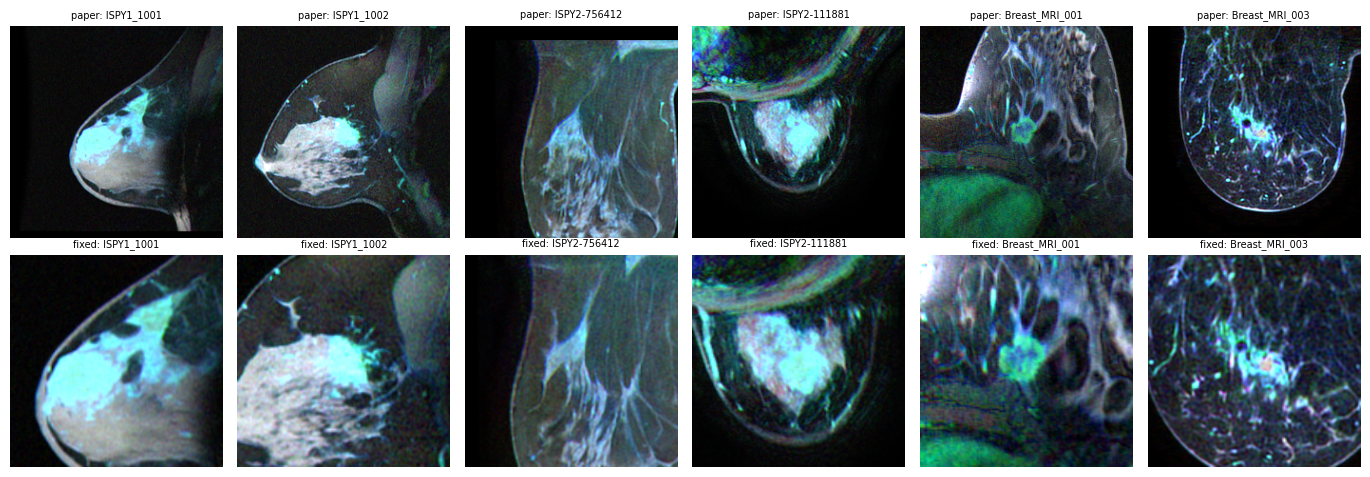

[06:55:04 | 0.07 h elapsed, 10.93 h left] train 1098 (321 pCR), val 177 (53 pCR); ViT folds 5, stage-2 folds 25


In [11]:
import torch
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LAB = META[META.labeled & META.split.isin(["train", "val"])].copy()          # never the test split (D-012)
if DEBUG:
    LAB = pd.concat([g.sample(min(len(g), 25), random_state=0) for _, g in LAB.groupby(["split", "cohort"])])
FILES = mc.cache_files(CACHES, list(LAB.pid))
say(f"1. 2D RGB slices for {len(FILES)} labelled train/val patients: paper ({PAPER_SLICES} middle slices, "
    f"{IMG_SIZE} native pixels) and fixed (up to {FIX_MAX_SLICES} tumour slices, {FIX_CROP_MM:.0f} mm field of view)")
from concurrent.futures import ProcessPoolExecutor, as_completed
rows, t = [], time.time()
with ProcessPoolExecutor(JOBS) as ex:
    futs = [ex.submit(m3d.make_slices, p, c, f, META.loc[p].to_dict(), mc.clip_of(CACHES[c]["index"], p), IMG_SIZE,
                      PAPER_SLICES, FIX_MAX_SLICES, FIX_CROP_MM) for p, (c, f) in FILES.items()]
    for i, fu in enumerate(as_completed(futs), 1):
        rows.append(fu.result())
        if i % 200 == 0 or i == len(futs):
            say(f"1. slices {i}/{len(futs)} ({(time.time() - t) / 60:.1f} min)")
OKR = sorted([r for r in rows if r["status"] == "ok"], key=lambda r: r["pid"])
PIDS = [r["pid"] for r in OKR]
ROW = {p: i for i, p in enumerate(PIDS)}

def stack(kind):
    n = [len(r[kind]) for r in OKR]
    off = np.r_[0, np.cumsum(n)]
    sl = [np.arange(off[i], off[i + 1]) for i in range(len(OKR))]
    area = np.concatenate([r["fixed_area"] if kind == "fixed" else np.ones(len(r[kind]), np.float32) for r in OKR])
    return np.concatenate([r[kind] for r in OKR]), sl, area.astype(np.float32)

DATA = {v: stack(v) for v in VARIANTS}
for r in rows:                                   # the stacked arrays are the only copy kept
    r.pop("paper", None), r.pop("fixed", None)
SQC = pd.DataFrame([{k: v for k, v in r.items() if not isinstance(v, np.ndarray)} for r in rows])
SQC.to_csv(f"{OUT}/slices_qc.csv", index=False)
print("status:", SQC.status.value_counts().to_dict())
if (SQC.status != "ok").any():
    print(SQC.loc[SQC.status != "ok", ["pid", "cohort", "note"]].head(10).to_string(index=False))
ok = SQC[SQC.status == "ok"]
print(ok.groupby("cohort").agg(patients=("pid", "size"), tumour_slices=("n_tumour_slices", "median"),
                               paper_slices=("n_paper", "mean"), fixed_slices=("n_fixed", "mean"),
                               paper_fov_mm=("paper_fov_mm", "median"), fixed_fov_mm=("fixed_fov_mm", "median"),
                               tumour_saturated=("tumour_saturated", "mean")).round(2).to_string())
for v, (imgs, sl, _) in DATA.items():
    print(f"{v}: {len(imgs)} slices, {imgs.nbytes / 1e9:.2f} GB")
show = [p for c in COH for p in ok[ok.cohort == c].pid.head(2)]
fig, axes = plt.subplots(2, len(show), figsize=(2.3 * len(show), 4.8), squeeze=False)
for j, p in enumerate(show):
    for i, v in enumerate(["paper", "fixed"]):
        if v in DATA:
            imgs, sl, _ = DATA[v]
            s = sl[ROW[p]]
            axes[i][j].imshow(imgs[s[len(s) // 2]])
        axes[i][j].axis("off")
        axes[i][j].set_title(f"{v}: {p}"[:24], fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/slice_examples.png", dpi=110); plt.show()

LAB = LAB[LAB.pid.isin(PIDS)].reset_index(drop=True)
LAB["label"] = LAB.pCR.astype(int)
TR, VA = LAB[LAB.split == "train"].reset_index(drop=True), LAB[LAB.split == "val"].reset_index(drop=True)
Y = TR.label.to_numpy(int)
R_TR, R_VA = np.array([ROW[p] for p in TR.pid]), np.array([ROW[p] for p in VA.pid])
HR_TR, HER2_TR = pd.to_numeric(TR.HR, errors="coerce").to_numpy(float), pd.to_numeric(TR.HER2, errors="coerce").to_numpy(float)
FOLDS = mc.make_folds(TR.cohort + "_" + TR.label.astype(str), 2 if DEBUG else STAGE2_REPEATS, seed=SEED)
VIT_FOLDS = [f for f in FOLDS if f[0] < (1 if DEBUG else VIT_REPEATS)]      # stage 2's first repeat = the ViT's folds
MODELS = {}
lk = m2e.lookup_preds(TR, VA, FOLDS)
MODELS["subtype lookup"] = {"oof": lk[0], "fold_auc": lk[1], "val": lk[2]}
say(f"train {len(TR)} ({Y.sum()} pCR), val {len(VA)} ({VA.label.sum()} pCR); ViT folds {len(VIT_FOLDS)}, stage-2 folds {len(FOLDS)}")

## 2. ViT fine-tuning, 5-fold CV on the training patients (GPU, ~6-10 min per fold)
Every slice carries its patient's label; each fold is early-stopped on an inner 15% of its training patients.

[06:55:05 | 0.07 h elapsed, 10.93 h left] 2. ViT 'paper': facebook/vit-mae-base, pCR + HR + HER2 heads, 5 folds


config.json:   0%|          | 0.00/676 [00:00<?, ?B/s]

[transformers] You are using a model of type `vit_mae` to instantiate a model of type `vit`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


model.safetensors: reconstructing file:   0%|          |  0.00B /  448MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

... (34 outputs left out)

[transformers] You are using a model of type `vit_mae` to instantiate a model of type `vit`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: facebook/vit-mae-base
Key                                                                     | Status     |  | 
------------------------------------------------------------------------+------------+--+-
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.layernorm_after.weight  | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.attention.o_proj.weight | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.layernorm_after.bias    | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.mlp.fc2.bias            | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.attention.k_proj.weight | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.attention.q_proj.bias   | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.attention.o_proj.bias   | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.layernorm_before.bias   | UNEXPECTED |  | 
decoder.decoder_layers.{0,

[07:33:54 | 0.71 h elapsed, 10.29 h left]      epoch 1/12: loss 0.9945, inner AUC 0.558 (2985 slices, 0.6 min)
[07:34:29 | 0.72 h elapsed, 10.28 h left]      epoch 2/12: loss 0.9720, inner AUC 0.580 (2985 slices, 0.6 min)
[07:35:03 | 0.73 h elapsed, 10.27 h left]      epoch 3/12: loss 0.9680, inner AUC 0.582 (2985 slices, 0.6 min)
[07:35:38 | 0.74 h elapsed, 10.26 h left]      epoch 4/12: loss 0.9279, inner AUC 0.573 (2985 slices, 0.6 min)
[07:36:13 | 0.75 h elapsed, 10.25 h left]      epoch 5/12: loss 0.8866, inner AUC 0.598 (2985 slices, 0.6 min)
[07:36:48 | 0.76 h elapsed, 10.24 h left]      epoch 6/12: loss 0.8350, inner AUC 0.582 (2985 slices, 0.6 min)
[07:37:23 | 0.77 h elapsed, 10.23 h left]      epoch 7/12: loss 0.7464, inner AUC 0.592 (2985 slices, 0.6 min)
[07:37:58 | 0.78 h elapsed, 10.22 h left]      epoch 8/12: loss 0.7283, inner AUC 0.591 (2985 slices, 0.6 min)
[07:38:34 | 0.79 h elapsed, 10.21 h left] 2. fixed fold 4: fold AUC 0.562 (best epoch 5, inner 0.598) | 24.5 min

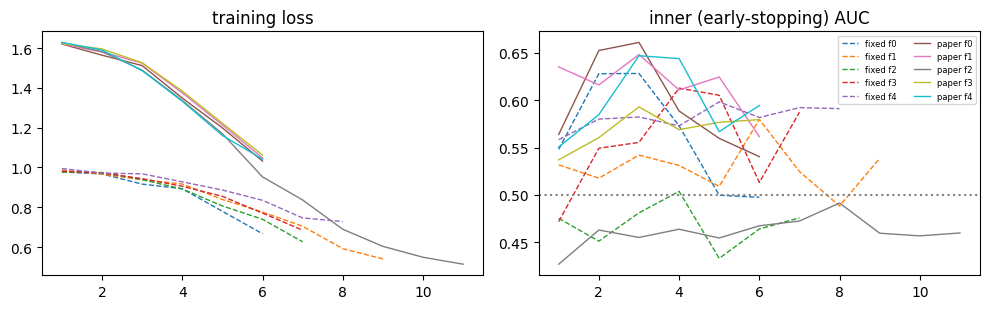

In [12]:
SCORE_COL = {"paper": 0, "fixed": 3}          # paper: mean of the slice probabilities; fixed: area-weighted mean
DL, VLOG, HIST = {}, [], []
for var in VARIANTS:
    IMGS, SL, AREA = DATA[var]
    reps = max(r for r, *_ in VIT_FOLDS) + 1
    oof, vals, fa = np.full((reps, len(TR), 4), np.nan), [], []
    t = time.time()
    say(f"2. ViT '{var}': {BACKBONE}, {'pCR + HR + HER2 heads' if MULTITASK[var] else 'pCR head'}, {len(VIT_FOLDS)} folds")
    for r, f, a, b in VIT_FOLDS:
        if budget_left() < 1.0:
            say(f"2. time budget nearly used: '{var}' stops after {len(fa)} folds"); break
        (pb, pv), ep, ain, hist = m3v.train_fold(
            BACKBONE, IMGS, SL, AREA, R_TR[a], Y[a], HR_TR[a], HER2_TR[a], [R_TR[b], R_VA], multitask=MULTITASK[var],
            train_slices=None if var == "paper" else TRAIN_SLICES, epochs=2 if DEBUG else EPOCHS, patience=PATIENCE,
            batch=BATCH, lr_backbone=LR_BACKBONE, lr_head=LR_HEAD, wd=WD, seed=SEED + 10 * r + f, dev=DEV, say=say)
        oof[r, b], vals = pb, vals + [pv]
        fa.append(mc.auc(Y[b], pb[:, SCORE_COL[var]]))
        VLOG.append({"variant": var, "repeat": r, "fold": f, "best_epoch": ep, "inner_auc": ain, "fold_auc": fa[-1],
                     **{f"fold_auc_{k}": mc.auc(Y[b], pb[:, j]) for j, k in enumerate(m3v.SCORES)}})
        HIST += [{"variant": var, "repeat": r, "fold": f, **h} for h in hist]
        say(f"2. {var} fold {f}: fold AUC {fa[-1]:.3f} (best epoch {ep + 1}, inner {ain:.3f}) | {(time.time() - t) / 60:.1f} min")
    if fa:
        DL[var] = {"oof": np.nanmean(oof, 0), "val": np.mean(vals, 0), "fold_auc": fa}
        o, v = DL[var]["oof"], DL[var]["val"]
        MODELS[f"{var} ViT: image only"] = {"oof": o[:, SCORE_COL[var]], "fold_auc": fa, "val": v[:, SCORE_COL[var]]}
        say(f"2. {var} ViT image only: cv {np.mean(fa):.3f} | oof " +
            ", ".join(f"{k} {mc.auc(Y, o[:, j]):.3f}" for j, k in enumerate(m3v.SCORES)) +
            " | val " + ", ".join(f"{k} {mc.auc(VA.label, v[:, j]):.3f}" for j, k in enumerate(m3v.SCORES)))
pd.DataFrame(VLOG).to_csv(f"{OUT}/vit_folds.csv", index=False)
H = pd.DataFrame(HIST)
H.to_csv(f"{OUT}/vit_epochs.csv", index=False)
if len(H):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
    for (var, f), g in H.groupby(["variant", "fold"]):
        axes[0].plot(g.epoch + 1, g.loss, "-" if var == "paper" else "--", lw=1)
        axes[1].plot(g.epoch + 1, g.inner_auc, "-" if var == "paper" else "--", lw=1, label=f"{var} f{f}")
    axes[0].set_title("training loss"); axes[1].set_title("inner (early-stopping) AUC"); axes[1].axhline(0.5, color="gray", ls=":")
    axes[1].legend(fontsize=6, ncol=2); plt.tight_layout(); plt.savefig(f"{OUT}/vit_curves.png", dpi=110); plt.show()

## 3. Stage 2: patient-level scores + clinical data + tumour size -> Random Forest / logistic regression

In [13]:
BASE_TR = pd.concat([mc.clinical_frame(TR), m3s.size_frame(TR)], axis=1).reset_index(drop=True)
BASE_VA = pd.concat([mc.clinical_frame(VA), m3s.size_frame(VA)], axis=1).reset_index(drop=True)
CLIN = [c for c in BASE_TR.columns if c.startswith("clin_")]

def dl_frames(var):
    cols = [f"{var}_vit_{k}" for k in m3v.SCORES]
    return pd.DataFrame(DL[var]["oof"], columns=cols), pd.DataFrame(DL[var]["val"], columns=cols)

SSL = None
if USE_STEP15:
    for f in sorted(glob.glob("/kaggle/input/**/stack_inputs.csv", recursive=True)):
        s = pd.read_csv(f, dtype={"pid": str})
        if "m2_probe_img" in s.columns:
            SSL = s.set_index("pid")["m2_probe_img"]
            say(f"3. step-15 self-supervised 3D score found: {f}")
            break
    if SSL is None:
        say("3. no step-15 output attached: the stage-2 sets without the self-supervised 3D score only")

SETS = {"clinical": (BASE_TR[CLIN], BASE_VA[CLIN]), "clinical + size": (BASE_TR, BASE_VA)}
for var in DL:
    a, b = dl_frames(var)
    SETS[f"clinical + size + {var} ViT"] = (pd.concat([BASE_TR, a], axis=1), pd.concat([BASE_VA, b], axis=1))
if SSL is not None:
    s_tr, s_va = TR.pid.map(SSL).to_numpy(float), VA.pid.map(SSL).to_numpy(float)
    SETS["clinical + size + SSL 3D (step 15)"] = (BASE_TR.assign(ssl3d=s_tr), BASE_VA.assign(ssl3d=s_va))
    if "fixed" in DL:
        a, b = dl_frames("fixed")
        SETS["clinical + size + fixed ViT + SSL 3D"] = (pd.concat([BASE_TR.assign(ssl3d=s_tr), a], axis=1),
                                                        pd.concat([BASE_VA.assign(ssl3d=s_va), b], axis=1))
for name, (A, B) in SETS.items():
    for kind in STAGE2_KINDS:
        r = m3s.cv_refit(A.to_numpy(float), Y, FOLDS, B.to_numpy(float), kind, SEED, JOBS)
        MODELS[f"{name} ({kind.upper()})"] = r
        say(f"3. {name} ({kind.upper()}), {A.shape[1]} features: cv {np.nanmean(r['fold_auc']):.3f} | oof "
            f"{mc.auc(Y, r['oof']):.3f} (within subtype {mc.within_auc(Y, r['oof'], TR.subtype):.3f}) | val "
            f"{mc.auc(VA.label, r['val']):.3f}")
if "clinical + size (RF)" in MODELS:          # what the Random Forest relies on (the paper's Figure 4)
    A, _ = SETS[max((k for k in SETS if "ViT" in k), default="clinical + size", key=len)]
    rf = m3s.make("rf", SEED).fit(A.to_numpy(float), Y)
    imp = pd.Series(rf.named_steps["rf"].feature_importances_[:A.shape[1]], index=A.columns).sort_values(ascending=False)
    print("\nRandom Forest feature importance (largest set, refit on all training patients):")
    print(imp.round(3).to_string())
    imp.to_csv(f"{OUT}/rf_feature_importance.csv")

[07:38:36 | 0.79 h elapsed, 10.21 h left] 3. no step-15 output attached: the stage-2 sets without the self-supervised 3D score only
[07:38:49 | 0.80 h elapsed, 10.20 h left] 3. clinical (RF), 7 features: cv 0.674 | oof 0.674 (within subtype 0.540) | val 0.658
[07:38:50 | 0.80 h elapsed, 10.20 h left] 3. clinical (LR), 7 features: cv 0.686 | oof 0.682 (within subtype 0.558) | val 0.638
[07:39:02 | 0.80 h elapsed, 10.20 h left] 3. clinical + size (RF), 9 features: cv 0.688 | oof 0.690 (within subtype 0.569) | val 0.660
[07:39:03 | 0.80 h elapsed, 10.20 h left] 3. clinical + size (LR), 9 features: cv 0.702 | oof 0.698 (within subtype 0.593) | val 0.660
[07:39:17 | 0.80 h elapsed, 10.20 h left] 3. clinical + size + paper ViT (RF), 13 features: cv 0.681 | oof 0.686 (within subtype 0.570) | val 0.647
[07:39:19 | 0.80 h elapsed, 10.20 h left] 3. clinical + size + paper ViT (LR), 13 features: cv 0.699 | oof 0.697 (within subtype 0.595) | val 0.672
[07:39:33 | 0.81 h elapsed, 10.19 h left] 3. c

## 4. The paper's Table 2 layout, and I-SPY2-only models

In [14]:
def pick(names):
    return [n for n in names if n in MODELS]

SHOW = pick(["subtype lookup", "clinical (LR)", "clinical + size (RF)", "paper ViT: image only", "fixed ViT: image only",
             "clinical + size + paper ViT (RF)", "clinical + size + paper ViT (LR)", "clinical + size + fixed ViT (RF)",
             "clinical + size + fixed ViT (LR)", "clinical + size + fixed ViT + SSL 3D (LR)",
             "clinical + size + fixed ViT + SSL 3D (RF)"])
PT_VAL = pd.concat([m3s.paper_table(VA, MODELS[m]["val"], THRESHOLD).assign(model=m) for m in SHOW])
PT_OOF = pd.concat([m3s.paper_table(TR, MODELS[m]["oof"], THRESHOLD).assign(model=m) for m in SHOW])
cols = ["model", "group", "n", "n_pcr", "pcr_rate", "acc", "acc_if_all_no_pcr", "auc", "auc_lo", "auc_hi", "sens", "spec",
        "prec", "npv"]
PT_VAL, PT_OOF = PT_VAL[cols], PT_OOF[cols]
PT_VAL.to_csv(f"{OUT}/paper_style_val.csv", index=False)
PT_OOF.to_csv(f"{OUT}/paper_style_train_oof.csv", index=False)
print(f"Paper-style table, VAL (177), threshold {THRESHOLD} (compare acc with acc_if_all_no_pcr):")
for m in SHOW:
    print(f"\n== {m}")
    print(PT_VAL[PT_VAL.model == m].drop(columns="model").round(3).to_string(index=False))

# I-SPY2 only, like the paper's "I-SPY2 with clinical features" (their extra MammaPrint / drug-arm columns are not public)
ITR, IVA = (TR.cohort == "ispy2").to_numpy(), (VA.cohort == "ispy2").to_numpy()
FOLDS_I = mc.make_folds(TR[ITR].label.to_numpy(), 2 if DEBUG else STAGE2_REPEATS, seed=SEED + 1)
ISPY, rows_i = {}, []
for name in [n for n in ("clinical + size", "clinical + size + paper ViT", "clinical + size + fixed ViT") if n in SETS]:
    A, B = SETS[name]
    for kind in STAGE2_KINDS:
        r = m3s.cv_refit(A.to_numpy(float)[ITR], Y[ITR], FOLDS_I, B.to_numpy(float)[IVA], kind, SEED, JOBS)
        ISPY[f"I-SPY2 only: {name} ({kind.upper()})"] = r
        t_ = m3s.paper_table(VA[IVA].reset_index(drop=True), r["val"], THRESHOLD)
        rows_i.append(t_[t_.group.isin(["overall", "subtype TN", "subtype HER2+", "subtype HR+/HER2-"])]
                      .assign(model=f"{name} ({kind.upper()})", train_cv=np.nanmean(r["fold_auc"]),
                              train_oof=mc.auc(Y[ITR], r["oof"])))
PT_ISPY = pd.concat(rows_i)[["model", "group", "train_cv", "train_oof"] + cols[2:]] if rows_i else pd.DataFrame()
PT_ISPY.to_csv(f"{OUT}/ispy2_only_val.csv", index=False)
print(f"\nI-SPY2-only models (train on {ITR.sum()} I-SPY2 patients, val = {IVA.sum()} I-SPY2 val patients):")
print(PT_ISPY.round(3).to_string(index=False))

Paper-style table, VAL (177), threshold 0.5 (compare acc with acc_if_all_no_pcr):

== subtype lookup
            group   n  n_pcr  pcr_rate   acc  acc_if_all_no_pcr   auc  auc_lo  auc_hi  sens  spec  prec   npv
          overall 177     53     0.299 0.701              0.701 0.662   0.575   0.740   0.0   1.0   NaN 0.701
       subtype TN  63     18     0.286 0.714              0.714 0.500   0.500   0.500   0.0   1.0   NaN 0.714
    subtype HER2+  49     24     0.490 0.510              0.510 0.500   0.500   0.500   0.0   1.0   NaN 0.510
subtype HR+/HER2-  65     11     0.169 0.831              0.831 0.500   0.500   0.500   0.0   1.0   NaN 0.831
     cohort ispy1  33     11     0.333 0.667              0.667 0.674   0.488   0.852   0.0   1.0   NaN 0.667
     cohort ispy2  99     32     0.323 0.677              0.677 0.638   0.522   0.738   0.0   1.0   NaN 0.677
      cohort duke  45     10     0.222 0.778              0.778 0.717   0.530   0.889   0.0   1.0   NaN 0.778

== clinical (LR)
 

## 5. Summary and paired comparisons

                           model  cv_auc  cv_sd  oof_auc  oof_within_subtype  oof_within_cohort  val_auc  val_ci_lo  val_ci_hi  val_within_subtype  val_within_cohort  oof_ispy1  oof_ispy2  oof_duke  val_ispy1  val_ispy2  val_duke  oof_vs_lookup  oof_vs_lookup_p
            clinical + size (LR)   0.702  0.032    0.698               0.593              0.690    0.660      0.573      0.745               0.546              0.671      0.755      0.688     0.723      0.711      0.664     0.686          0.069            0.000
clinical + size + fixed ViT (LR)   0.701  0.033    0.699               0.599              0.690    0.684      0.597      0.768               0.589              0.696      0.755      0.687     0.711      0.740      0.694     0.677          0.070            0.000
clinical + size + paper ViT (LR)   0.699  0.033    0.697               0.595              0.688    0.672      0.582      0.756               0.571              0.684      0.750      0.685     0.715      0.731      

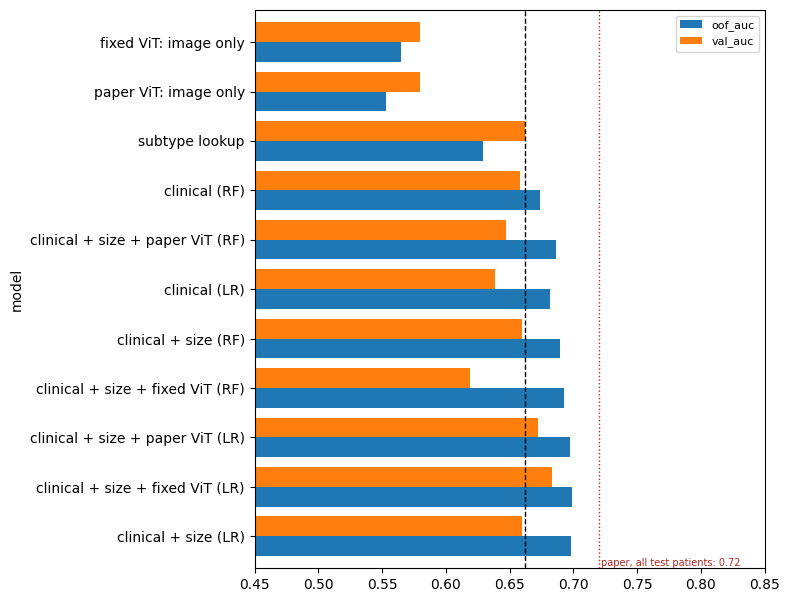

                                   model   n  pcr   auc  ci_lo  ci_hi  auprc  brier   ece  sens@90spec  ppv@90spec  npv@90spec  diff_vs_ref  delong_ci_lo  delong_ci_hi  delong_p  boot_p
                          subtype lookup 177   53 0.662  0.579  0.745  0.411  0.198 0.061        0.000         NaN       0.701          NaN           NaN           NaN       NaN     NaN
                   step16: clinical (LR) 177   53 0.638  0.548  0.728  0.455  0.197 0.025        0.264        0.56       0.743       -0.024        -0.085         0.038     0.450   0.430
step16: clinical + size + paper ViT (RF) 177   53 0.647  0.562  0.732  0.399  0.202 0.098        0.151        0.40       0.713       -0.015        -0.093         0.063     0.709   0.682
            step16: clinical + size (LR) 177   53 0.660  0.573  0.747  0.449  0.195 0.054        0.226        0.50       0.732       -0.002        -0.066         0.061     0.944   0.939


In [15]:
for k_, m in MODELS.items():   # a ViT stopped by the time budget leaves NaN OOF for some patients: fill with the median
    if np.isnan(m["oof"]).any():
        m["oof"] = np.where(np.isnan(m["oof"]), np.nanmedian(m["oof"]), m["oof"])
PAIRS = [("subtype lookup -> clinical (LR)", "subtype lookup", "clinical (LR)"),
         ("clinical (LR) -> clinical + size (LR)", "clinical (LR)", "clinical + size (LR)"),
         ("clinical + size: LR -> RF", "clinical + size (LR)", "clinical + size (RF)"),
         ("paper ViT -> fixed ViT (image only)", "paper ViT: image only", "fixed ViT: image only"),
         ("clinical + size -> + paper ViT (RF, the paper's pipeline)", "clinical + size (RF)", "clinical + size + paper ViT (RF)"),
         ("clinical + size -> + paper ViT (LR)", "clinical + size (LR)", "clinical + size + paper ViT (LR)"),
         ("clinical + size -> + fixed ViT (LR)", "clinical + size (LR)", "clinical + size + fixed ViT (LR)"),
         ("+ paper ViT -> + fixed ViT (LR)", "clinical + size + paper ViT (LR)", "clinical + size + fixed ViT (LR)"),
         ("clinical + size -> + fixed ViT + SSL 3D (LR)", "clinical + size (LR)", "clinical + size + fixed ViT + SSL 3D (LR)"),
         ("clinical (LR) -> best image + clinical (LR)", "clinical (LR)", "clinical + size + fixed ViT + SSL 3D (LR)")]
STACK = {"s16_paper_vit": "paper ViT: image only", "s16_fixed_vit": "fixed ViT: image only"}
note = (f"Train {len(TR)} / val {len(VA)}. ViT: {len(VIT_FOLDS)}-fold CV on the training patients (OOF), val = mean of "
        f"the fold models; stage 2: {2 if DEBUG else STAGE2_REPEATS} x 5-fold CV + refit for val. The test split is never "
        f"loaded. Caches: " + ", ".join(f"{c} {v['kind']}" for c, v in CACHES.items()))
RES, CMPS = m2e.report(TR, VA, MODELS, PAIRS, OUT, "Step 16 results: the BreastDCEDL paper's ViT pipeline, as published and fixed",
                       note, STACK)
print(RES.round(3).to_string(index=False))
print("\nPaired comparisons (b - a, same patients):")
print(CMPS.round(3).to_string(index=False))
r = RES.set_index("model")[["oof_auc", "val_auc"]]
ax = r.plot.barh(figsize=(8, 0.42 * len(r) + 1.5), width=0.8)
ax.axvline(0.662, ls="--", lw=1, color="k"); ax.axvline(0.72, ls=":", lw=1, color="#b3261e")
ax.text(0.722, -0.6, "paper, all test patients: 0.72", color="#b3261e", fontsize=7)
ax.set_xlim(0.45, 0.85); ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{OUT}/auc_by_model.png", dpi=120); plt.show()

CMP = None
try:
    def as_preds(col):
        V = pd.read_csv(f"{OUT}/val_preds.csv", dtype={"pid": str})
        return V[["pid", "cohort", "label"]].assign(prob=V[col].values)
    best = RES[RES.model != "subtype lookup"].iloc[0].model
    preds = {"B1 LR (clinical + size)": B1_VAL, "subtype lookup": as_preds("subtype lookup"), "F2 fusion v1 (old cache)": F2_V1}
    preds.update({f"{STEP}: {k_}": as_preds(k_) for k_ in dict.fromkeys(
        ["clinical (LR)", "clinical + size + paper ViT (RF)", best]) if k_ in MODELS})
    CMP = compare(preds, "subtype lookup")
    print(CMP.round(3).to_string(index=False))
    CMP.to_csv(f"{OUT}/comparison_vs_team.csv", index=False)
except Exception as e:
    print("comparison with the team's models skipped:", type(e).__name__, e)

## How to read the results against the paper
- **Same metric, same kind of set:** the paper's all-cohort test AUC is **0.72** (177 patients). Compare it with our
  `val_auc` (177 different patients, same size) and, better, with `oof_auc` (all 1,098 training patients, much less
  noise). Their test set's cohort counts (I-SPY1 35, I-SPY2 99, Duke 43) match our held-out test split, which this
  notebook never touches.
- **Accuracy:** read `acc` against `acc_if_all_no_pcr`. In a subgroup with 12.5% pCR, 87.5% accuracy needs no model.
- **Subgroup AUCs:** look at `n_pcr` and the CI (`auc_lo`-`auc_hi`). With 5 pCR cases even an AUC of 0.94 has a
  95% CI of roughly 0.8-1.0.
- **What could still explain a gap:** their I-SPY2 model used MammaPrint and the drug arm (not in the public data),
  and the subgroup / model they report was the best of many on one split.

## 6. Results file

In [16]:
txt = open(f"{OUT}/RESULTS.md").read()
txt += ("\n## Paper-style table (val, threshold %.2f): compare `acc` with `acc_if_all_no_pcr`\n\n" % THRESHOLD
        + mc.md_table(PT_VAL) + "\n")
if len(PT_ISPY):
    txt += "\n## I-SPY2-only models (val = 99 I-SPY2 patients)\n\n" + mc.md_table(PT_ISPY) + "\n"
if CMP is not None:
    txt += "\n## Best models vs the team's models (val, paired DeLong vs the subtype lookup)\n\n" + mc.md_table(CMP) + "\n"
open(f"{OUT}/RESULTS_step16.md", "w").write(txt)
say(f"wrote {OUT}/RESULTS_step16.md (+ paper_style_val.csv, ispy2_only_val.csv, vit_folds.csv, stack_inputs.csv)")

[07:41:28 | 0.84 h elapsed, 10.16 h left] wrote /kaggle/working/results/vaib/step16/RESULTS_step16.md (+ paper_style_val.csv, ispy2_only_val.csv, vit_folds.csv, stack_inputs.csv)


In [17]:
# ==== PUSH the small result files to the vaib branch (results/<PERSON>/...) ====
if PUSH_RESULTS and not _tok:
    print("PUSH_RESULTS needs the GITHUB_TOKEN secret; download results/ from the Output tab instead")
elif PUSH_RESULTS and not DEBUG:
    git("config", "user.name", f"Person {PERSON} (Kaggle)")
    git("config", "user.email", "kaggle@users.noreply.github.com")
    for attempt in range(3):
        git("fetch", "--quiet", "--depth", "1", "origin", f"+refs/heads/{GIT_TAG}:refs/remotes/origin/{GIT_TAG}")
        git("checkout", "--quiet", "-f", "-B", GIT_TAG, f"origin/{GIT_TAG}")
        shutil.copytree(f"/kaggle/working/results/{PERSON}", f"results/{PERSON}", dirs_exist_ok=True)
        git("add", f"results/{PERSON}")
        print(git("commit", "-m", f"results: {PERSON} {NOTEBOOK_NAME} ({GIT_TAG})"))
        try:
            git("push", "--quiet", "origin", GIT_TAG); print("pushed to", GIT_TAG); break
        except RuntimeError as e:
            print(f"push attempt {attempt + 1} failed:", e)
    else:
        print("NOT pushed: download results/ from the Output tab")